# GUIDE Dataset — Preprocessing & Statistical Evaluation

Dataset: `microsoft/microsoft-security-incident-prediction` (GUIDE_Train.csv / GUIDE_Test.csv).

This notebook covers:
1. Loading & basic inspection
2. Missing value analysis
3. Duplicate handling
4. Type/feature preprocessing (timestamp, categoricals)
5. Statistical evaluation (describe, class balance, correlations)

Model training is intentionally **not** included — that comes in a later pass.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
import glob

pd.set_option('display.max_columns', 100)
sns.set_theme(style='whitegrid')

matches = glob.glob('/kaggle/input/**/GUIDE_Train.csv', recursive=True)
if not matches:
    raise FileNotFoundError('GUIDE_Train.csv not found under /kaggle/input')
DATA_DIR = os.path.dirname(matches[0])
print('Using DATA_DIR =', DATA_DIR)
print(os.listdir(DATA_DIR))

Using DATA_DIR = /kaggle/input/datasets/Microsoft/microsoft-security-incident-prediction
['GUIDE_Test.csv', 'GUIDE_Test_Queue_Rankings.csv', 'GUIDE_Train.csv']


## 1. Load data

In [2]:
train = pd.read_csv(f'{DATA_DIR}/GUIDE_Train.csv')
test = pd.read_csv(f'{DATA_DIR}/GUIDE_Test.csv')
rankings = pd.read_csv(f'{DATA_DIR}/GUIDE_Test_Queue_Rankings.csv')

print('Train shape:', train.shape)
print('Test shape:', test.shape)
print('Rankings shape:', rankings.shape)
train.head()

/tmp/ipykernel_16/20142253.py:2: DtypeWarning: Columns (10,11) have mixed types. Specify dtype option on import or set low_memory=False.
  test = pd.read_csv(f'{DATA_DIR}/GUIDE_Test.csv')


Train shape: (9516837, 45)
Test shape: (4147992, 46)
Rankings shape: (9980, 3)


,Id,OrgId,IncidentId,AlertId,Timestamp,DetectorId,AlertTitle,Category,MitreTechniques,IncidentGrade,ActionGrouped,ActionGranular,EntityType,EvidenceRole,DeviceId,Sha256,IpAddress,Url,AccountSid,AccountUpn,AccountObjectId,AccountName,DeviceName,NetworkMessageId,EmailClusterId,RegistryKey,RegistryValueName,RegistryValueData,ApplicationId,ApplicationName,OAuthApplicationId,ThreatFamily,FileName,FolderPath,ResourceIdName,ResourceType,Roles,OSFamily,OSVersion,AntispamDirection,SuspicionLevel,LastVerdict,CountryCode,State,City
0,180388628218,0,612,123247,2024-06-04T06:05:15.000Z,7,6,InitialAccess,NaN,TruePositive,NaN,NaN,Ip,Related,98799,138268,27,160396,441377,673934,425863,453297,153085,529644,NaN,1631,635,860,2251,3421,881,NaN,289573,117668,3586,NaN,NaN,5,66,NaN,NaN,NaN,31,6,3
1,455266534868,88,326,210035,2024-06-14T03:01:25.000Z,58,43,Exfiltration,NaN,FalsePositive,NaN,NaN,User,Impacted,98799,138268,360606,160396,22406,23032,22795,24887,153085,529644,NaN,1631,635,860,2251,3421,881,NaN,289573,117668,3586,NaN,NaN,5,66,NaN,NaN,NaN,242,1445,10630
2,1056561957389,809,58352,712507,2024-06-13T04:52:55.000Z,423,298,InitialAccess,T1189,FalsePositive,NaN,NaN,Url,Related,98799,138268,360606,68652,441377,673934,425863,453297,153085,529644,NaN,1631,635,860,2251,3421,881,NaN,289573,117668,3586,NaN,NaN,5,66,NaN,Suspicious,Suspicious,242,1445,10630
3,1279900258736,92,32992,774301,2024-06-10T16:39:36.000Z,2,2,CommandAndControl,NaN,BenignPositive,NaN,NaN,Url,Related,98799,138268,360606,13,441377,673934,425863,453297,153085,529644,NaN,1631,635,860,2251,3421,881,NaN,289573,117668,3586,NaN,NaN,5,66,NaN,Suspicious,Suspicious,242,1445,10630
4,214748368522,148,4359,188041,2024-06-15T01:08:07.000Z,9,74,Execution,NaN,TruePositive,NaN,NaN,User,Impacted,98799,138268,360606,160396,449,592,440,479,153085,529644,NaN,1631,635,860,2251,3421,881,NaN,289573,117668,3586,NaN,NaN,5,66,NaN,NaN,NaN,242,1445,10630


## 2. Basic inspection

In [3]:
print('Memory usage (MB):', train.memory_usage(deep=True).sum() / 1e6)
train.info()

Memory usage (MB): 8273.99647
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9516837 entries, 0 to 9516836
Data columns (total 45 columns):
 #   Column              Dtype  
---  ------              -----  
 0   Id                  int64  
 1   OrgId               int64  
 2   IncidentId          int64  
 3   AlertId             int64  
 4   Timestamp           object 
 5   DetectorId          int64  
 6   AlertTitle          int64  
 7   Category            object 
 8   MitreTechniques     object 
 9   IncidentGrade       object 
 10  ActionGrouped       object 
 11  ActionGranular      object 
 12  EntityType          object 
 13  EvidenceRole        object 
 14  DeviceId            int64  
 15  Sha256              int64  
 16  IpAddress           int64  
 17  Url                 int64  
 18  AccountSid          int64  
 19  AccountUpn          int64  
 20  AccountObjectId     int64  
 21  AccountName         int64  
 22  DeviceName          int64  
 23  NetworkMessageId    int64  

## 3. Missing value analysis

ResourceType         99.925658
ActionGrouped        99.410897
ActionGranular       99.410897
ThreatFamily         99.213173
EmailClusterId       98.982729
AntispamDirection    98.136965
Roles                97.707736
SuspicionLevel       84.825536
LastVerdict          76.523030
MitreTechniques      57.460120
IncidentGrade         0.539465
dtype: float64


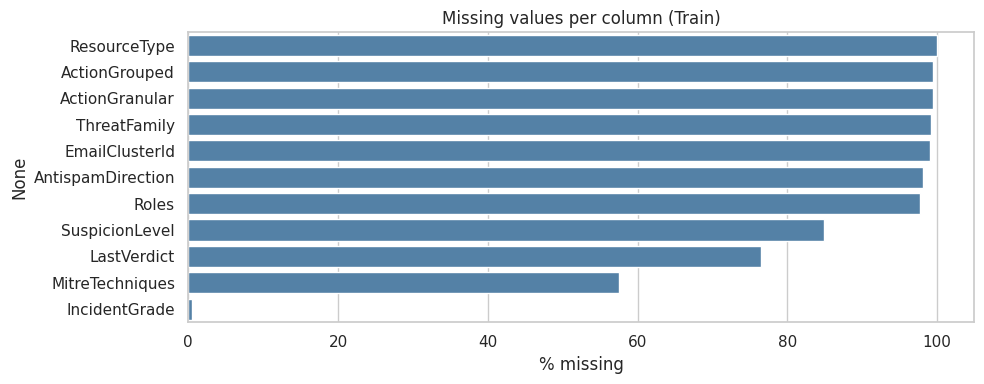

In [4]:
missing = train.isna().mean().sort_values(ascending=False) * 100
missing = missing[missing > 0]
print(missing)

plt.figure(figsize=(10, max(4, len(missing) * 0.25)))
sns.barplot(x=missing.values, y=missing.index, color='steelblue')
plt.xlabel('% missing')
plt.title('Missing values per column (Train)')
plt.tight_layout()
plt.show()

## 4. Duplicate rows

In [5]:
dupe_count = train.duplicated().sum()
print(f'Duplicate rows: {dupe_count} ({dupe_count / len(train):.4%})')
train = train.drop_duplicates().reset_index(drop=True)
print('Shape after dropping duplicates:', train.shape)

Duplicate rows: 22559 (0.2370%)
Shape after dropping duplicates: (9494278, 45)


## 5. Preprocessing
- Drop columns that are almost entirely missing (>95%)
- Parse `Timestamp` into datetime features
- Cast low-cardinality object columns to `category`

In [6]:
high_missing_cols = missing[missing > 95].index.tolist()
print('Dropping high-missing columns:', high_missing_cols)
train = train.drop(columns=high_missing_cols)

train['Timestamp'] = pd.to_datetime(train['Timestamp'], errors='coerce')
train['Hour'] = train['Timestamp'].dt.hour
train['DayOfWeek'] = train['Timestamp'].dt.dayofweek
train['Date'] = train['Timestamp'].dt.date

object_cols = train.select_dtypes(include='object').columns
low_card_cols = [c for c in object_cols if train[c].nunique() <= 50]
for c in low_card_cols:
    train[c] = train[c].astype('category')

print('Low-cardinality columns cast to category:', low_card_cols)
train.dtypes

Dropping high-missing columns: ['ResourceType', 'ActionGrouped', 'ActionGranular', 'ThreatFamily', 'EmailClusterId', 'AntispamDirection', 'Roles']
Low-cardinality columns cast to category: ['Category', 'IncidentGrade', 'EntityType', 'EvidenceRole', 'SuspicionLevel', 'LastVerdict']


Id                                  int64
OrgId                               int64
IncidentId                          int64
AlertId                             int64
Timestamp             datetime64[ns, UTC]
DetectorId                          int64
AlertTitle                          int64
Category                         category
MitreTechniques                    object
IncidentGrade                    category
EntityType                       category
EvidenceRole                     category
DeviceId                            int64
Sha256                              int64
IpAddress                           int64
Url                                 int64
AccountSid                          int64
AccountUpn                          int64
AccountObjectId                     int64
AccountName                         int64
DeviceName                          int64
NetworkMessageId                    int64
RegistryKey                         int64
RegistryValueName                 

## 6. Statistical evaluation

In [7]:
train.describe(include='number').T

,count,mean,std,min,25%,50%,75%,max
Id,9494278.0,8.431532e+11,4.966756e+11,0.0,4.123169e+11,8.418136e+11,1.271310e+12,1.709397e+12
OrgId,9494278.0,1.819008e+02,3.871802e+02,0.0,1.000000e+01,4.400000e+01,1.720000e+02,6.147000e+03
IncidentId,9494278.0,7.082839e+04,1.209298e+05,0.0,5.120000e+02,1.044900e+04,8.466400e+04,5.997060e+05
AlertId,9494278.0,4.067742e+05,4.596960e+05,0.0,2.305800e+04,2.164080e+05,6.727278e+05,1.721456e+06
DetectorId,9494278.0,1.109075e+02,4.355892e+02,0.0,2.000000e+00,9.000000e+00,4.500000e+01,9.522000e+03
AlertTitle,9494278.0,2.953860e+03,1.147403e+04,0.0,2.000000e+00,1.100000e+01,1.810000e+02,1.131740e+05
DeviceId,9494278.0,9.566797e+04,1.634152e+04,0.0,9.879900e+04,9.879900e+04,9.879900e+04,9.879900e+04
Sha256,9494278.0,1.287089e+05,3.401052e+04,0.0,1.382680e+05,1.382680e+05,1.382680e+05,1.382680e+05
IpAddress,9494278.0,2.857942e+05,1.411893e+05,0.0,3.606060e+05,3.606060e+05,3.606060e+05,3.606060e+05
Url,9494278.0,1.503080e+05,3.754887e+04,0.0,1.603960e+05,1.603960e+05,1.603960e+05,1.603960e+05


In [8]:
train.describe(include='category').T

,count,unique,top,freq
Category,9494278,20,InitialAccess,4275023
IncidentGrade,9442956,3,BenignPositive,4110748
EntityType,9494278,33,Ip,2175106
EvidenceRole,9494278,2,Related,5193267
SuspicionLevel,1441733,2,Suspicious,1440218
LastVerdict,2231836,5,Suspicious,1401964


### Target class balance — `IncidentGrade`

                  count    pct
IncidentGrade                 
BenignPositive  4110748  43.30
TruePositive    3302644  34.79
FalsePositive   2029564  21.38
NaN               51322   0.54


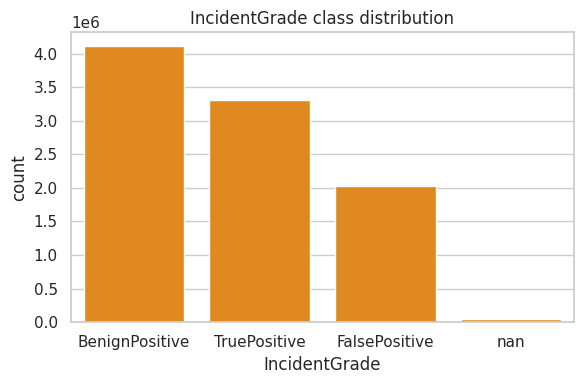

In [9]:
target_counts = train['IncidentGrade'].value_counts(dropna=False)
target_pct = train['IncidentGrade'].value_counts(normalize=True, dropna=False) * 100
print(pd.DataFrame({'count': target_counts, 'pct': target_pct.round(2)}))

plt.figure(figsize=(6, 4))
sns.barplot(x=target_counts.index.astype(str), y=target_counts.values, color='darkorange')
plt.title('IncidentGrade class distribution')
plt.ylabel('count')
plt.tight_layout()
plt.show()

### Category / entity distributions

In [10]:
for col in ['Category', 'EntityType', 'EvidenceRole']:
    print(f'--- {col} ---')
    print(train[col].value_counts().head(10))
    print()

--- Category ---
Category
InitialAccess         4275023
Exfiltration          1577926
SuspiciousActivity    1003879
CommandAndControl      826691
Impact                 750885
CredentialAccess       298189
Execution              267594
Malware                142032
Discovery              129336
Persistence             72682
Name: count, dtype: int64

--- EntityType ---
EntityType
Ip                   2175106
User                 1926333
MailMessage          1173140
Machine               698182
File                  687003
Url                   682562
CloudLogonRequest     632503
Mailbox               483152
Process               345730
MailCluster           224677
Name: count, dtype: int64

--- EvidenceRole ---
EvidenceRole
Related     5193267
Impacted    4301011
Name: count, dtype: int64



### Correlation structure (numeric features)

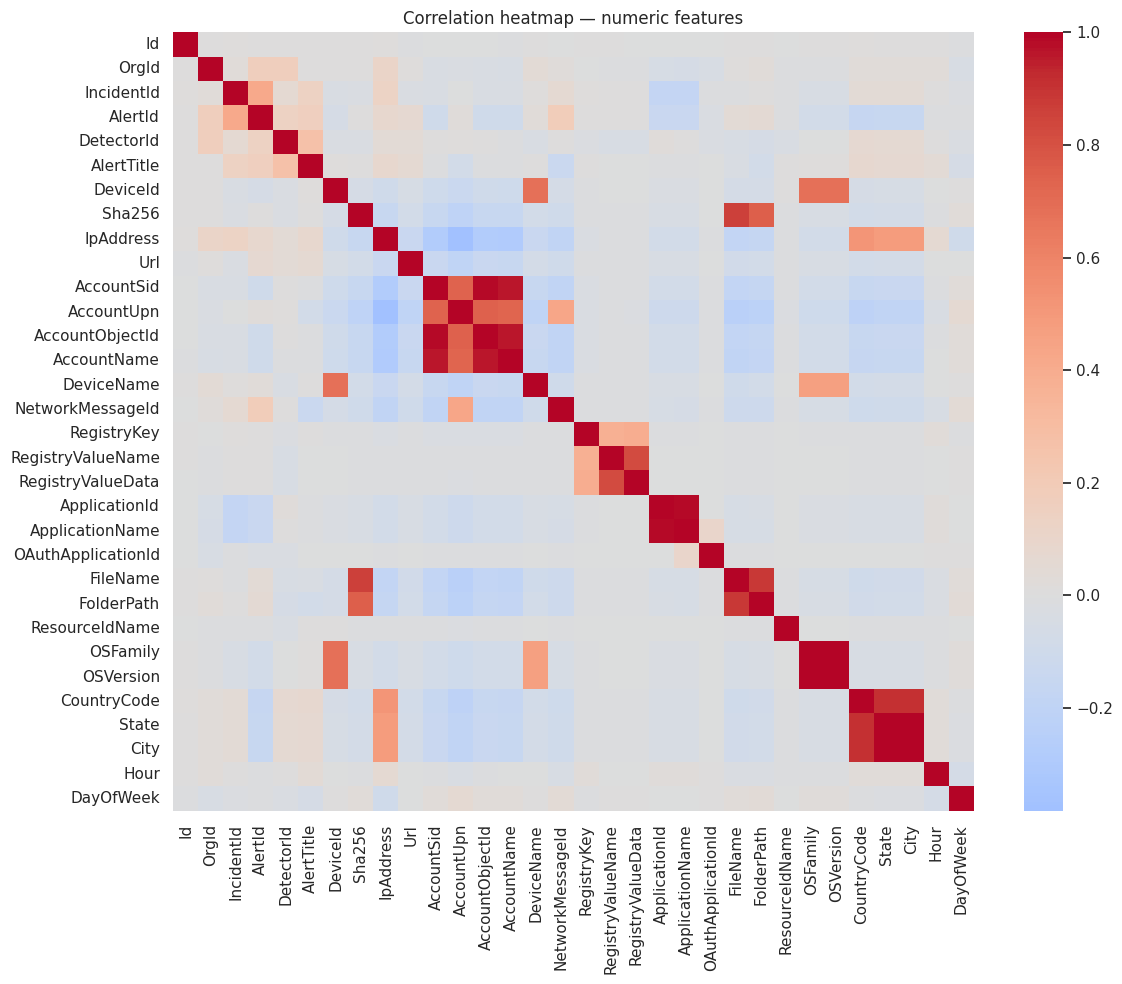

In [11]:
numeric_df = train.select_dtypes(include='number')
corr = numeric_df.corr(numeric_only=True)

plt.figure(figsize=(12, 10))
sns.heatmap(corr, cmap='coolwarm', center=0, annot=False)
plt.title('Correlation heatmap — numeric features')
plt.tight_layout()
plt.show()

### IncidentGrade vs. Category crosstab

In [12]:
crosstab = pd.crosstab(train['Category'], train['IncidentGrade'], normalize='index') * 100
crosstab.round(1)

IncidentGrade,BenignPositive,FalsePositive,TruePositive
Category,,,
Collection,38.2,48.9,13.0
CommandAndControl,68.3,17.6,14.1
CredentialAccess,39.9,23.9,36.2
CredentialStealing,0.0,97.7,2.3
DefenseEvasion,46.4,30.4,23.2
Discovery,55.7,26.7,17.5
Execution,50.3,32.9,16.8
Exfiltration,69.7,23.8,6.5
Exploit,56.1,13.0,30.9


## 7. Summary

- Reported missing-value rates and dropped columns above the 95% missing threshold.
- Removed exact duplicate rows.
- Parsed `Timestamp` into `Hour` / `DayOfWeek` / `Date` features.
- Cast low-cardinality text columns to `category` for memory efficiency.
- Computed descriptive statistics, target class balance, category distributions, and a numeric correlation heatmap.

Next step (future task): feature engineering + model training/evaluation on `IncidentGrade`.